# Lab05: Games

## Overview of the lab

In this lab, we will learn to solve games in which we have perfect information.

## 1. Games
* ***Perfect Information (Knowledge of Moves)***: Every player knows every move that has ever been made by all players up to the current point in the game. Think of it as no hidden history;

* ***Complete Information (Knowledge of Rules/Payoffs)***: Every player knows the rules, possible strategies, and payoff structure for every player. Think of it as no hidden types/incentives; everyone knows what everyone else stands to gain or lose. 

|                          | deterministic  | chance           | 
|----                      | ----           |      ----        |
| **perfect information**  | chess, go      | monopoly         |
| **complete information** | batteships     | pocker, scrabble |

### Is it true that if the game has a perfect information it also has a compelete information?

* Perfect Information:	**All past moves.** Every player knows the entire history of actions taken in the game up to the current moment. (No hidden action).	Chess. Both players see every piece and every move made on the board.
* Complete Information	**All game rules/payoffs/types.** Every player knows the incentives (utility functions/payoffs) and strategies available to all other players. (No hidden rules/goals).

NO! 

**The Game:** Imagine a sequential bargaining game where Player 1 makes a proposal, and Player 2 accepts or rejects it.

* Perfect Information? Yes. Player 2 sees Player 1's proposal (the action). If Player 2 rejects, Player 1 sees the rejection. All moves are transparent.

* Complete Information? Maybe Not. Player 1 might not know the exact minimum amount Player 2 is willing to accept (Player 2's payoff/type). Player 2's threshold is private, hidden information.

## 2. Minimax 

Its core principle is to **minimize the maximum possible loss** for the current player, assuming the opponent will always play optimally to maximize their own gain (and thus minimize your score).

The name "Minimax" comes from the recursive alternation between two roles:
1. MAX (Player1): Tries to Maximize the score.
2. MIN (Player2): Tries to Minimize the score.

### Game Tree 
Graph Representation: A game tree is a directed graph where:

* **Nodes** represent a possible state of the game (e.g., a board configuration).
* **Edges** represent a move from one game state to the next.

### Minimax summarised:

1. Minimax is a decision-making tool for two-player turn-taking games
2. Minimax exploress a game tree by anticipating future moves. 
3. Minimax uses an Evaluation Function to assign scores to board states. 
4. Minimax strategically chooses the optimal path trough Recusrsive Exploration and Backtracking.


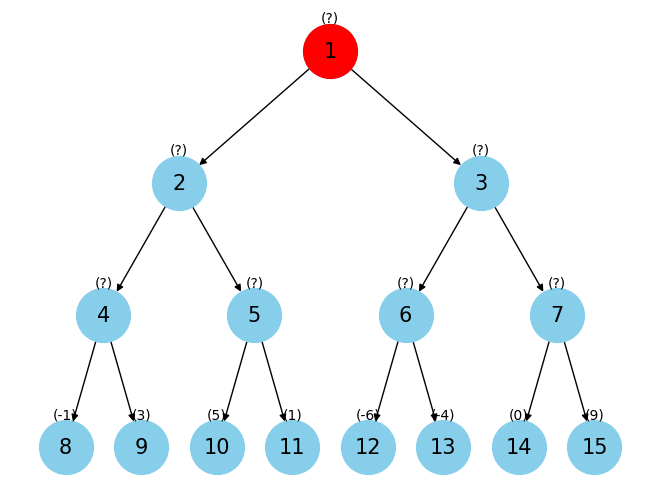

In [1]:
from utils import Graph
edges = {
    1: [(2, 1), (3, 1)],
    2: [(4, 1), (5, 1)],
    3: [(6, 1), (7, 1)],
    4: [(8, 1), (9, 1)],
    5: [(10, 1), (11, 1)],
    6: [(12, 1), (13, 1)],
    7: [(14, 1), (15, 1)]
}
nodes = list(range(1,15))
heuristic = {
    1: "?",
    2: "?",
    3: "?",
    4: "?",
    5: "?",
    6: "?",
    7: "?",
    8: -1,
    9: 3,
    10: 5,
    11: 1,
    12: -6,
    13: -4,
    14: 0,
    15: 9,
}
graph = Graph(nodes,edges,heuristic=heuristic,start_node=1,is_tree=True)
graph.show(show_weights=False,display_graph_name=False,heuristic_offset=0.05)


In [2]:
def min_max(edges,heuristic,current,is_max=True):

    if not current in edges:
        return heuristic[current]
    
    best_value = float("inf") if not is_max else float("-inf")
    for successors,cost in edges[current]:
        value = min_max(edges,heuristic,successors,not is_max)

        if is_max and value > best_value:
            best_value = value
        
        if not is_max and value < best_value:
            best_value = value

    heuristic[current] = best_value
    return best_value

Best value: 3


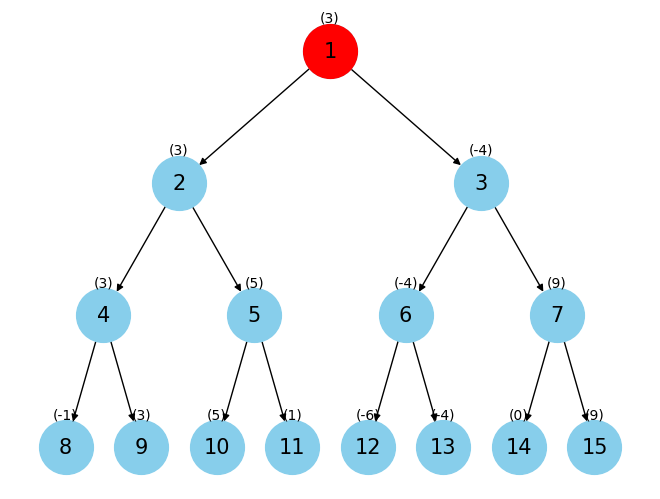

In [3]:
print("Best value:",min_max(edges,heuristic,graph.start_node))
graph.show(show_weights=False,display_graph_name=False,heuristic_offset=0.05)


## Properties of minimax
 
**Complete?**  **Yes***, if the tree is finite

----

**Optimal?** - Yes, against an optimal opponent
Conditions under which Minimax is optimal:

### Conditions for Minimax Optimality

The Minimax algorithm guarantees the optimal move *for the worst-case scenario* against a rational opponent, provided the following conditions hold true:

* **Two-Player**
   * Only two players are involved.
   * The core $\max/\min$ structure breaks down with more players.
* **Zero-Sum** 
   * The gain of one player is exactly the loss of the other.
   * The $\max$ player's goal (maximize my score) is exactly the inverse of the $\min$ player's goal (minimize my opponent's score).
* **Perfect Information**
   * Both players know the entire state of the game (e.g., Chess, Checkers, Tic-Tac-Toe).
   * the game involves hidden information (e.g., Poker), Minimax is no longer guaranteed to be optimal; other methods like Expected Minimax is needed.
* **Deterministic** 
   * There is no element of chance (no dice, shuffled cards, etc.).
   * If chance is involved, a variant called Expectimax is used, where the Minimax layers are interspersed with 'chance nodes' that calculate expected values.
* **Complete Search**
   * The algorithm must be able to search all the way to a terminal (game-ending) state.
   * In real-world games like Chess, this is impossible. The algorithm stops at a fixed depth (the search horizon) and uses a heuristic (evaluation function) to estimate the value of the non-terminal nodes, making the result only heuristically optimal (an approximation).


*Minimax is typically used in classical games like Chess, Checkers, and Tic-Tac-Toe.*

The moment any of the above conditions are violated, or a practical limitation is introduced, Minimax ceases to be the "optimal" strategy:

* **Against a Suboptimal Opponent:** Minimax will still win, but it might miss an opportunity to win faster or more decisively. If you know your opponent is weak, you could choose a "trap" move that Minimax rejects (because a perfect opponent would avoid the trap), but that an imperfect opponent is likely to fall for. 

* **Limited Search Depth:** As noted above, if the search is cut short by an arbitrary depth limit (which is necessary for complex games), the result is only as good as the heuristic evaluation function used at the leaves.

----

**Time complexity** - $O(b^m)$

----
**Space complexity** - $O(bm)$

## Alpha-Beta pruning

### Do we need to evaluate the whole game tree?

![alpha_beta_1](images/alpha_beta_pruning.png)

$\alpha$ - the best value that MAX can garantee at the current level and the levels above (upper levels)

$\beta$ - the best value that MIN can garantee at the current level and the levels above\

**Recuirement for pruning**: $\beta \leq \alpha$ 
 * Min had a better option available earlier in the tree

### Properties of Alpha-Beta Pruning
* Pruning does not affect final result.
* Good move ordering improves effectiveness of pruning

In [4]:
def alpha_beta(edges, heuristic, current, alpha, beta,is_max=True):

    if not current in edges:
        return heuristic[current]
    
    best_value = float("inf") if not is_max else float("-inf")

    for successors,cost in edges[current]:
        value = alpha_beta(edges,heuristic,successors,alpha,beta,not is_max)

        if is_max and value > best_value:
            best_value = value
            alpha = max(alpha,value)
        
        if not is_max and value < best_value:
            best_value = value
            beta = min(beta,value)

        if alpha >= beta:  # PRUNE
                break

    heuristic[current] = best_value

    return heuristic[current]

Best value: 3


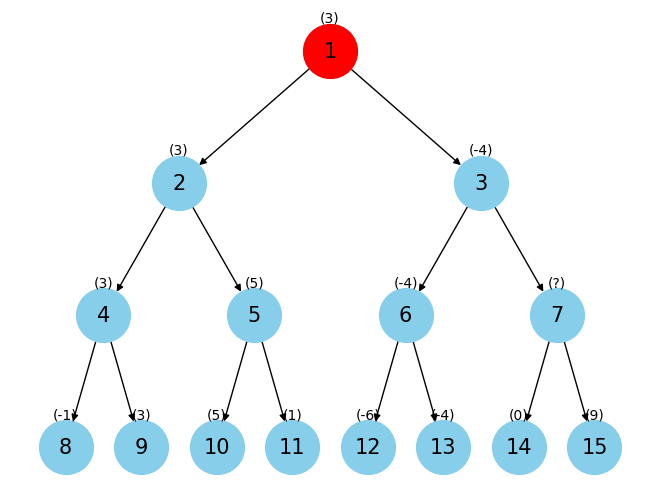

In [9]:
edges = {
    1: [(2, 1), (3, 1)],
    2: [(4, 1), (5, 1)],
    3: [(6, 1), (7, 1)],
    4: [(8, 1), (9, 1)],
    5: [(10, 1), (11, 1)],
    6: [(12, 1), (13, 1)],
    7: [(14, 1), (15, 1)]
}
nodes = list(range(1,15))
heuristic = {
    1: "?",
    2: "?",
    3: "?",
    4: "?",
    5: "?",
    6: "?",
    7: "?",
    8: -1,
    9: 3,
    10: 5,
    11: 1,
    12: -6,
    13: -4,
    14: 0,
    15: 9,
}
graph = Graph(nodes,edges,heuristic=heuristic,start_node=1,is_tree=True)
print("Best value:",alpha_beta(edges,heuristic,graph.start_node,float("-inf"),float("inf")))
graph.show(show_weights=False,display_graph_name=False,heuristic_offset=0.05)

## Homework: Tic-Tac-Toe
Implement a game of Tic-Tac-Toe against an opponent using the Min-Max algorithm
with Alpha-Beta Pruning.
It starts with a blank board.
At each step:
- One player enters two numbers ([1,3]) from a keyboard which are his or her turn on
the board;
- Using the algorithm, we find our move;
- Then the specific status of the game is displayed.
  
Finally, it shows who won the game.

### What Heuristic Should We Use?

A simple heuristic for this game is to assign a score of **1** if player O wins, **0** if the game ends in a draw, and **-1** if player X wins. This is a valid approach because the standard Minimax algorithm with alpha-beta pruning can explore the entire game tree without much difficulty.

For games with much larger state spaces, exploring the entire game tree may be too computationally expensive. In such cases, we need to introduce a **cutoff criterion** to limit the search depth and use an evaluation function to estimate the value of non-terminal states.

However, this heuristic has one limitation: it does not guarantee that the algorithm will find a winning strategy that wins in the fewest possible moves. Since all wins have the same score, the algorithm has no reason to prefer a faster victory over a slower one.


### How to guarantee that we always win with the fewest amount of moves possible:

A better heuristic that takes the number of moves into consideration is:

- $10 - Depth$ if O wins

- $Depth - 10$ if X wins

- 0 if draw

The score will be adjusted based on the number of moves made and the player whose perspective is being considered. This encourages the Minimax algorithm to choose moves that lead to the fastest possible victory while delaying defeat for as long as possible.